In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget
%pwd

'/projectnb/batmanlab/mragoza/lung-project/notebooks/IPMI-2027'

In [2]:
import sys, os

def add_path(path):
    if path not in sys.path:
        sys.path.append(path)

add_path(os.environ['LP_ROOT'])
add_path(os.environ['PROJECT'] + '/' + 'param_search')

import project
import param_search as ps
import evaluation

ps.set_backend('sge')
ps.set_verbose(False)

import torch
torch.cuda.is_available()

True

# Phantom reconstruction

In [3]:
%autoreload
base_prefix = '../copdgene/2026-11-18'
protocol_keys = ['params.forward_mat', 'params.inverse_mat']

material_types = ['LE', 'NH']
eval_phase = 'test'

subject_split = {
    'train': ['10049K', '10056H', '10081G', '10096T', '10114V', '10124Y', '10127E', '10130T', '10153F', '10155J', '10179X', '10181K', '10196X', '10211T', '10212V', '10213X', '10217F', '10227I', '10233D', '10245K', '10261I', '10265Q', '10301U', '10314D', '10328O', '10332F', '10367Y', '10372R', '10395D', '10426O', '10458B', '10469G', '10481W', '10502E', '10503G', '10507O', '10512H', '10523M', '10524O', '10539B', '10552T', '10560S', '10561U', '10564A', '10566E', '10567G', '10572Z', '10624S', '10635X', '10641S', '10646C', '10663C', '10679R', '10699X', '10705S', '10724W', '10736D', '10761C', '10794R', '10815Z', '10829K', '10842C', '10843E', '10883Q', '10887Y', '10888A', '10908G', '10919L', '10947Q', '10961K', '10973R', '10975V', '10990R', '11005V', '11007Z', '11027F', '11049P', '11063J', '11085T', '11114A', '11120V', '11123B', '11139Q', '11153K', '11193W', '11198G', '11211Y', '11221B', '11224H', '11225J', '11226L', '11235M', '11240F', '11247T', '11260L', '11267Z', '11281T', '11329V', '11350M', '11363V', '11404J', '11455A', '11468J', '11477K', '11498S', '11506R', '11514Q', '11516U', '11545B', '11560X', '11600J', '11613S', '11616Y', '11618C', '11676Q', '11690K', '11708D', '11713W', '11716C', '11721V', '11743F', '11746L', '11752G', '11782P', '11783R', '11815E', '11819M', '11828N', '11830A', '11850G', '11852K', '11858W', '11866V', '11879E', '11881R', '11901X', '11903B', '11943N', '11947V', '11972U', '11998M', '12052J', '12069A', '12146S', '12187G', '12231J', '12294H', '12339D', '12362Y', '12418Z', '12457J', '12466K', '12477P', '12478R', '12515X', '12516Z', '12519F', '12560C', '12599D', '12607C', '12608E', '12651F', '12676V', '12683S', '12696B', '12816L', '12825M', '12831H', '12851N', '12878H', '12895H', '12903G', '12905K', '12962W', '12964A', '13034M', '13053Q', '13065X', '13071S', '13084B', '13092A', '13093C', '13103F', '13111E', '13149D', '13170U', '13242T', '13248F', '13267J', '13273E', '13282F', '13297S', '13301J', '13340T', '13341V', '13350W', '13354E', '13358M', '13365J', '13370C', '13383L', '13384N', '13398Y', '13404T', '13407Z', '13419G', '13428H', '13460D', '13488Z', '13489B', '13498C', '13501R', '13507D', '13517G', '13528L', '13542F', '13563N', '13586Z', '13632G', '13651K', '13682V', '13686D', '13702B', '13704F', '13719S', '13728T', '13736S', '13767D', '13780V', '13816Q', '13845X', '13864B', '13866F', '13901H', '13916U', '13925V', '13945B', '13947F', '13998W', '14013J', '14031L', '14047A', '14075F', '14084G', '14113N', '14121M', '14133T', '14157H', '14173F', '14180C', '14194N', '14201K', '14217Z', '14232V', '14241W', '14257L', '14278T', '14293P', '14307A', '14309E', '14329K', '14332Z', '14386W', '14390N', '14417H', '14462M', '14471N', '14508K', '14525K', '14526M', '14632L', '14633N', '14646W', '14668G', '14683C', '14684E', '14685G', '14704K', '14705M', '14729A', '14732P', '14771Z', '14774F', '14814R', '14817X', '14834X', '14845C', '14857J', '14863E', '14875L', '14880E', '14909C', '14964K', '14987W', '14991N', '15040R', '15073G', '15075K', '15078Q', '15082H', '15088T', '15102N', '15140V', '15152C', '15156K', '15163H', '15164J', '15165L', '15204V', '15212U', '15217E', '15221V', '15224B', '15232A', '15237K', '15262J', '15271K', '15297C', '15312Y', '15349V', '15350G', '15357U', '15384X', '15450K', '15473W', '15488J', '15489L', '15502D', '15527T', '15532M', '15537W', '15549D', '15607R', '15623P', '15635W', '15650S', '15661X', '15690E', '15699W', '15745D', '15799A', '15807Z', '15811Q', '15827F', '15840X', '15848N', '15885T', '15894U', '15900P', '15909H', '15911U', '15929N', '15934G', '15965R', '16021S', '16045G', '16059R', '16060C', '16065M', '16069U', '16091N', '16118H', '16266W', '16300W', '16347W', '16353R', '16402E', '16411F', '16440M', '16472Z', '16527Y', '16540Q', '16573F', '16605S', '16637F', '16675N', '16700M', '16716B', '16747M', '16783Q', '16853L', '16954R', '16977D', '17011U', '17022Z', '17041D', '17089F', '17104B', '17137Q', '17144N', '17173U', '17212E', '17233M', '17255W', '17266B', '17337Y', '17366F', '17385J', '17409X', '17414Q', '17428B', '17433U', '17461Z', '17473G', '17505T', '17509B', '17557M', '17573K', '17617E', '17629L', '17696A', '17722B', '17757U', '17790S', '17836Q', '17847V', '17862R', '17894E', '17897K', '17920F', '17922J', '17939A', '17952S', '17955Y', '17995K', '18015H', '18043M', '18103E', '18126Q', '18140K', '18153T', '18184E', '18278N', '18317X', '18374J', '18395R', '18403Q', '18434B', '18451B', '18452D', '18505Y', '18515B', '18525E', '18553J', '18563M', '18629Q', '18633H', '18674V', '18677B', '18682U', '18687E', '18703C', '18761Q', '18786G', '18798N', '18801C', '18830J', '18845W', '18935X', '18960W', '18982G', '19049D', '19059G', '19091C', '19139E', '19143V', '19251Y', '19324Z', '19339M', '19356M', '19367R', '19396Y', '19410S', '19415C', '19478A', '19549X', '19558Y', '19560L', '19594C', '19598K', '19612E', '19637U', '19666B', '19673Y', '19679K', '19760T', '19783F', '19784H', '19785J', '19819A', '19839G', '19849J', '19880D', '19908Z', '19913S', '19922T', '19950Y', '20005W', '20006Y', '20019H', '20024A', '20064M', '20088A', '20102U', '20117H', '20149U', '20188E', '20195B', '20245Q', '20286E', '20306K', '20332L', '20349C', '20378J', '20385G', '20453X', '20519B', '20566K', '20589W', '20592L', '20609C', '20623W', '20632X', '20640W', '20668S', '20678V', '20682M', '20689A', '20703U', '20738N', '20748Q', '20792T', '20803Y', '20807G', '20867Y', '20901Y', '20970R', '20976D', '20977F', '21004Z', '21010U', '21012Y', '21042H', '21052K', '21065T', '21106H', '21150K', '21163T', '21168D', '21175A', '21176C', '21189L', '21223L', '21224N', '21272Y', '21279M', '21293G', '21384J', '21391G', '21398U', '21399W', '21410K', '21419C', '21433W', '21438G', '21461B', '21467N', '21469R', '21484N', '21494Q', '21508B', '21521T', '21526D', '21538K', '21556M', '21559S', '21572K', '21586V', '21587X', '21595W', '21604X', '21611U', '21614A', '21622Z', '21640B', '21647P', '21660H', '21741H', '21769D', '21778E', '21800X', '21813G', '21837U', '21844R', '21850M', '21877G', '21886H', '21897M', '21899Q', '21933Q', '21968J', '22002A', '22055V', '22078H', '22114L', '22116P', '22148C', '22193H', '22210H', '22224S', '22253Z', '22261Y', '22308Y', '22312P', '22325Y', '22357L', '22389Y', '22423Y', '22464M', '22483Q', '22484S', '22487Y', '22495X', '22497B', '22536L', '22592V', '22597F', '22600U', '22604C', '22617L', '22637R', '22663S', '22678F', '22726Q', '22736T', '22745U', '22746W', '22759F', '22827W', '22832P', '22855B', '22877L', '22891F', '22912N', '22920M', '22928C', '22946E', '22961A', '22986Q', '23023N', '23037Y', '23052U', '23074E', '23075G', '23091E', '23094K', '23108V', '23123R', '23124T', '23136A', '23150U', '23155E', '23165H', '23193M', '23239K', '23252C', '23266N', '23269T', '23284P', '23287V', '23293Q', '23310Q', '23326F', '23342D', '23436M', '23500V', '23526N', '23549Z', '23558A', '23574Y', '23577E', '23618S', '23636U', '23656A', '23657C', '23699S', '23705N', '23725T', '23743V', '23746B', '23799W', '23803N', '23816W', '23819C', '23821P', '23851Y', '23902P', '23934C', '24064G', '24080E', '24106W', '24113T', '24123W', '24137H', '24151B', '24154H', '24181K', '24186U', '24205Y', '24213X', '24271L', '24318L', '24331D', '24348U', '24350H', '24383W', '24390T', '24394B', '24438V', '24447W', '24449A', '24480U', '24514L', '24576H', '24581A', '24608U', '24638D', '24646C', '24652X', '24679R', '24682G', '24684K', '24691H', '24699X', '24705S', '24711N', '24714T', '24744C', '24757L', '24761C', '24763G', '24777R', '24810P', '24830V', '24867S', '24873N', '24911V', '24927K', '24950F', '24954N', '24989G', '25003R', '25007Z', '25051C', '25072K', '25096Y', '25120V', '25125F', '25130Y', '25231E', '25245P', '25276A', '25303D', '25309P', '25311C', '25328T', '25335Q', '25347X', '25360P', '25380V', '25381X', '25388L', '25389N', '25400B', '25407P', '25410E', '25454Y', '25552Y', '25601L', '25602N', '25674M', '25703T', '25728J', '25762J', '25767T', '25782P', '25888F', '25894A', '25900V', '25914G', '25923H', '25926N', '25943N', '25950K', '25991Y', '26004Y', '26012X', '26146S'],
    'test': ['10432J', '10490X', '10568I', '10571X', '10634V', '10709A', '10728E', '10880K', '11255S', '11353S', '11542V', '11750C', '12139V', '12147U', '12273Z', '12422Q', '12506W', '12593R', '12630X', '12795D', '12812D', '12861Q', '13264D', '13477U', '13573Q', '13799Q', '14374P', '14788Q', '14905U', '15272M', '15413E', '15617U', '15905Z', '16058P', '16064K', '16142E', '16277B', '16390X', '16463Y', '16514P', '17102X', '17247X', '17476M', '17904H', '18274F', '18341U', '18351X', '18498B', '18593V', '18714H', '18736R', '18808Q', '18886K', '18940Q', '19024N', '19393S', '19627R', '19686H', '19730K', '19912Q', '19921R', '20008C', '20296H', '20400C', '20529E', '20543Y', '20696X', '21170Q', '21534C', '21615C', '21679C', '21838W', '21892C', '22031H', '22113J', '22151R', '22198R', '22430V', '22667A', '22873D', '22914R', '22983K', '23077K', '23312U', '23615M', '23838G', '23930U', '23940X', '24269Y', '24279B', '24431H', '24887Y', '24973R', '25165R', '25320D', '25403H', '25704V', '25835K', '26066U', '26112B'],
    'val': ['10017X', '10020M', '10031R', '10478H', '10806Y', '10817D', '10849Q', '11099E', '11181P', '11195A', '11292Y', '11325N', '11440N', '11512M', '11556G', '11968D', '12223K', '12248A', '12336X', '13255C', '13530Y', '13533E', '13578A', '13648V', '14240U', '14261C', '14330V', '14380K', '14550J', '14745Y', '14754Z', '14837D', '14924Y', '15072E', '15132W', '15267T', '15319M', '15424J', '15606P', '15898C', '16076R', '16128K', '16132B', '16216H', '16294B', '16537B', '16546C', '16613R', '16823C', '17533Y', '17688B', '18364G', '18397V', '18519J', '18840M', '18871X', '19027T', '19056A', '19096M', '19429N', '19579G', '19733Q', '19887R', '20151H', '20375D', '20412J', '20435V', '20622U', '20659R', '20770J', '20818L', '20981W', '21064R', '21083V', '21153Q', '21765V', '21842N', '22092B', '22135T', '22170V', '22182C', '22348K', '22504Y', '22566U', '22720E', '23011G', '23181F', '23741R', '24012N', '24059N', '24116Z', '24377B', '24396F', '24562W', '24643W', '25205D', '25310A', '25694S', '25695U', '26071N'],
}

phantom_expt = evaluation.Experiment(base_prefix, protocol_keys, subject_split)
phantom_eval = phantom_expt.combine_metrics(phase='test')

Loading job metadata
Loading evaluation metrics


100%|██████████| 600/600 [00:01<00:00, 333.59it/s]


Selecting best train epochs


params.random_seed  epoch      loss
params.forward_mat params.inverse_mat                                     
LE                 LE                                   2      6  0.000487
NH                 LE                                   0      7  0.001523
                   NH                                   0      6  0.000599

In [4]:
# compute aggregate metrics
from scipy.stats import iqr

phantom_eval['protocol'] = (
    phantom_eval['params.forward_mat'] + ' → ' +
    phantom_eval['params.inverse_mat']
)

metric_keys = ['u_cell.nrmse', 'E_cell.nrmse', 'E_cell.pcorr']
group_keys = ['protocol', 'method']

phantom_eval.groupby(group_keys)[metric_keys] \
    .agg(['count', 'mean', 'std', 'median', iqr])

u_cell.nrmse                                          \
                         count      mean       std    median       iqr   
protocol method                                                          
LE → LE  Baseline          100  0.000973  0.000280  0.000924  0.000434   
         Ours              100  0.018343  0.009859  0.016102  0.008537   
NH → LE  Baseline          100  0.006099  0.002123  0.005879  0.002741   
         Ours              100  0.034650  0.016738  0.031964  0.014657   
NH → NH  Baseline          100  0.000965  0.000294  0.000912  0.000400   
         Ours              100  0.020770  0.012087  0.018579  0.009465   

                  E_cell.nrmse                                          \
                         count      mean       std    median       iqr   
protocol method                                                          
LE → LE  Baseline          100  0.142659  0.075130  0.112100  0.112147   
         Ours              100  0.151678  0.058264  0.145031  0.055199   
NH → LE  Baseline          100  0.822059  0.858049  0.498532  0.516060   
         Ours              100  0.228350  0.068436  0.211289  0.065461   
NH → NH  Baseline          100  0.141650  0.077888  0.111346  0.112617   
         Ours              100  0.160009  0.061882  0.152330  0.069017   

                  E_cell.pcorr                                          
                         count      mean       std    median       iqr  
protocol method                                                         
LE → LE  Baseline          100  0.960420  0.100557  0.978719  0.016625  
         Ours              100  0.884188  0.063774  0.897032  0.065966  
NH → LE  Baseline          100  0.517854  0.200577  0.513358  0.310286  
         Ours              100  0.819711  0.092669  0.849384  0.092558  
NH → NH  Baseline          100  0.971291  0.030925  0.979850  0.015625  
         Ours              100  0.877650  0.067407  0.889693  0.064677

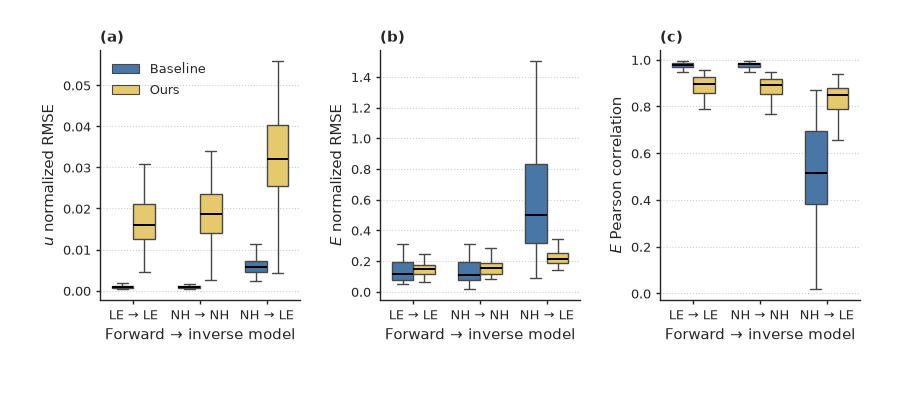

In [5]:
import matplotlib.pyplot as plt
import project.visual.matplotlib as mpl_viz
import seaborn as sns

sns.set_theme(style='ticks', context='paper', font_scale=1.1)
palette = {'Baseline': '#4477AA', 'Ours': '#EECC66'}

readable_names = {
    'E_vox.nrmse': '$E$ normalized RMSE',
    'E_vox.pcorr': '$E$ Pearson correlation',
    'E_vox.scorr': '$E$ rank correlation',
    'E_cell.nrmse': '$E$ normalized RMSE',
    'E_cell.pcorr': '$E$ Pearson correlation',
    'E_cell.scorr': '$E$ rank correlation',
    'u_cell.nrmse': '$u$ normalized RMSE',
}

protocol_order = ['LE → LE', 'NH → NH', 'NH → LE']
method_order = ['Baseline', 'Ours']

fig, axes = mpl_viz.subplot_grid(
    n_rows=1,
    n_cols=3,
    ax_height=2.5,
    ax_width=2,
    spacing=0.8,
    padding=(1.0, 0.5, 1.0, 0.5)
)

for col, metric in enumerate(metric_keys):
    ax = axes[0, col]

    sns.boxplot(
        data=phantom_eval,
        x='protocol',
        y=metric,
        hue='method',
        order=protocol_order,
        hue_order=method_order,
        palette=palette,
        saturation=0.9,
        width=0.65,
        showfliers=False,
        medianprops={'color': 'black', 'linewidth': 1.4},
        ax=ax
    )
    
    ax.set_xlabel('Forward → inverse model')
    ax.set_ylabel(readable_names[metric])
    ax.set_title(f'({chr(97 + col)})', loc='left', fontweight='bold')
    ax.grid(axis='y', linestyle=':')
    ax.set_axisbelow(True)
    ax.tick_params(axis='both', length=3)
    sns.despine(ax=ax)

    ax.get_legend().remove()

handles, labels = axes[0,0].get_legend_handles_labels()
axes[0,0].legend(handles, labels, frameon=False, ncols=1, loc='upper left')
plt.pause(1.0)

In [7]:
#fig.savefig('phantom_results_plot.png', bbox_inches='tight', dpi=400)
#fig.savefig('phantom_results_plot.pdf', bbox_inches='tight', dpi=400)

In [8]:
# subjects and rows contributing to each box plot
phantom_eval.groupby(['protocol', 'method']).agg(
    subjects=('subject', 'nunique'),
    rows=('subject', 'size'),
)

subjects  rows
protocol method                  
LE → LE  Baseline       100   100
         Ours           100   100
NH → LE  Baseline       100   100
         Ours           100   100
NH → NH  Baseline       100   100
         Ours           100   100

In [9]:
# TODO phantom reconstruction grid

In [10]:
#fig.savefig('2026-11-05_phantom_grid.png', bbox_inches='tight', dpi=400)
#fig.savefig('2026-11-05_phantom_grid.pdf', bbox_inches='tight', dpi=400)

# BMC-4DCT clinical evaluation

In [11]:
case_split = {
    'train': ['4DCT_10_1', '4DCT_1_1', '4DCT_2_1', '4DCT_2_2', '4DCT_4_1', '4DCT_6_1', '4DCT_7_3', '4DCT_8_1', '4DCT_8_2', 'unknown_12_1', 'unknown_13_1', 'unknown_14_1', 'unknown_16_1', 'unknown_20_1', 'unknown_23_1', 'unknown_26_1', 'unknown_32_1', 'unknown_34_1', 'unknown_36_1', 'unknown_37_1', 'unknown_38_1', 'unknown_42_1', 'unknown_42_4', 'unknown_44_1', 'unknown_45_1', 'unknown_49_1', 'unknown_50_1', 'unknown_52_1', 'unknown_53_1'],
    'test': ['unknown_17_1', 'unknown_17_3', 'unknown_28_1', 'unknown_29_1', 'unknown_30_1', 'unknown_31_1', 'unknown_33_1', 'unknown_43_1', 'unknown_47_1'],
    'val': ['unknown_15_1', 'unknown_18_1', 'unknown_19_1', 'unknown_22_1', 'unknown_27_1', 'unknown_39_1', 'unknown_40_1', 'unknown_40_5', 'unknown_51_1'],
}
base_prefix = '../bmc-4dct/2026-11-15'
protocol_keys = ['params.curr_phase', 'params.material_type']

bmc_expt = evaluation.Experiment(base_prefix, protocol_keys, case_split)

Loading job metadata
Loading evaluation metrics


100%|██████████| 324/324 [00:01<00:00, 172.29it/s]


Selecting best train epochs


params.random_seed  epoch      loss
params.curr_phase params.material_type                                     
0                 LE                                     0     23  0.041524
                  NH                                     0     16  0.040917
10                LE                                     0     23  0.059343
                  NH                                     0     25  0.059857
20                LE                                     0     23  0.098553
                  NH                                     0     23  0.099973
30                LE                                     0     21  0.136889
                  NH                                     0     25  0.137764
40                LE                                     0     14  0.217935
                  NH                                     0     16  0.219170
60                LE                                     2     12  0.209306
                  NH                                     0     19  0.206970
70                LE                                     2     17  0.139587
                  NH                                     0     20  0.141967
80                LE                                     2     23  0.078943
                  NH                                     2     23  0.078859
90                LE                                     0     19  0.040631
                  NH                                     2     19  0.040005

In [12]:
%%time
bmc_expt.load_assets(phase='test') # ~1 minute

Loading common assets
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-15_train/job_20dcd12aa42a2ede/config/7376b2cbfa0ad26e.yaml
dict(len=4)
├── 'dataset':       dict(len=6)
|   ├── 'name':          'BMC-4DCT'
|   ├── 'root':          '/restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT'
|   ├── 'subjects':      '4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4DCT_7_3,4DCT_8_1,4DCT_8_2,4DCT_10_1,unknown_12_1,unknown_13_1,unknown_14_1,unknown_15_1,unknown_16_1,unknown_17_1,unknown_17_3,unknown_18_1,unknown_19_1,unknown_20_1,unknown_22_1,unknown_23_1,unknown_26_1,unknown_27_1,unknown_28_1,unknown_29_1,unknown_30_1,unknown_31_1,unknown_32_1,unknown_33_1,unknown_34_1,unknown_36_1,unknown_37_1,unknown_38_1,unknown_39_1,unknown_40_1,unknown_40_5,unknown_42_1,unknown_42_4,unknown_43_1,unknown_44_1,unknown_45_1,unknown_47_1,unknown_49_1,unknown_50_1,unknown_51_1,unknown_52_1,unknown_53_1'
|   ├── 'state_pairs':   list(len=1)
|   |   └── 0: list(len=2)
|   |       ├

In [17]:
%%time
bmc_expt.evaluate_protocol((0, 'LE'), phase='test') # ~2 minutes

Evaluating protocol: (0, 'LE')
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-15_train/job_20dcd12aa42a2ede/config/7376b2cbfa0ad26e.yaml
dict(len=4)
├── 'dataset':       dict(len=6)
|   ├── 'name':          'BMC-4DCT'
|   ├── 'root':          '/restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT'
|   ├── 'subjects':      '4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4DCT_7_3,4DCT_8_1,4DCT_8_2,4DCT_10_1,unknown_12_1,unknown_13_1,unknown_14_1,unknown_15_1,unknown_16_1,unknown_17_1,unknown_17_3,unknown_18_1,unknown_19_1,unknown_20_1,unknown_22_1,unknown_23_1,unknown_26_1,unknown_27_1,unknown_28_1,unknown_29_1,unknown_30_1,unknown_31_1,unknown_32_1,unknown_33_1,unknown_34_1,unknown_36_1,unknown_37_1,unknown_38_1,unknown_39_1,unknown_40_1,unknown_40_5,unknown_42_1,unknown_42_4,unknown_43_1,unknown_44_1,unknown_45_1,unknown_47_1,unknown_49_1,unknown_50_1,unknown_51_1,unknown_52_1,unknown_53_1'
|   ├── 'state_pairs':   list(len=1)
|   |   └── 0: list(len=2)
|   

  0%|          | 0/9 [00:00<?, ?it/s]

Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-15_optimize/job_8a229f7f32b53d1b/outputs/optimize/default/unknown_17_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-15_optimize/job_bdf0ddc5ee60f433/outputs/optimize/default/unknown_17_3/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-15_optimize/job_e68ae849fd5a61d9/outputs/optimize/default/unknown_28_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-15_optimize/job_9102ae1eabf3be9b/outputs/optimize/default/unknown_29_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-15_optimize/job_ed8e9017c65aff94/outputs/optimize/default/unknown_30_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-15_optimize/job_f2ca3eddf83bd094/outputs/optimize/default/unknown_31_1/ra

In [18]:
region_eval = bmc_expt.get_region_eval()
region_eval

,params.curr_phase,params.material_type,subject,method,region,n_voxels,n_finite,mean,std,median,Q1,Q3,min,max
0,0,LE,unknown_17_1,Ours,pleural_effusion,334093,334093,24202.820312,38207.371094,2275.432861,402.324585,28128.789062,1.00000,100000.000000
1,0,LE,unknown_17_1,Ours,honeycombing,7,7,36.961445,20.346502,30.325556,22.837616,43.472137,16.27359,79.511436
2,0,LE,unknown_17_1,Ours,nodule,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0,LE,unknown_17_1,Ours,lt-850,22488,22488,5993.095215,17922.789062,449.035767,67.253838,2438.237061,1.00000,100000.000000
4,0,LE,unknown_17_1,Ours,lung_airways_wall,48927,48927,14405.814453,30891.671875,1086.472168,178.935059,5466.938965,1.00000,100000.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
337,0,LE,unknown_47_1,Baseline,abnormal,743247,743247,34675.460938,39933.285156,11415.004883,568.199707,74218.835938,0.00000,100000.015625
338,0,LE,unknown_47_1,Baseline,normal,5231694,5231694,25742.207031,34624.796875,5290.960938,492.878143,44398.503906,0.00000,100000.015625
339,0,LE,unknown_47_1,Baseline,harder,123251,123251,30217.873047,38096.734375,6117.634277,563.616272,59741.710938,0.00000,100000.015625
340,0,LE,unknown_47_1,Baseline,softer,614568,614568,35704.617188,40266.941406,13089.060547,593.581177,77605.203125,1.00000,100000.015625


In [20]:
#region_eval.to_csv('BMC_main_region_eval.csv', index=False)
#region_eval = pd.read_csv('BMC_main_region_eval.csv')

/scratch/8767267.1.batcomputer/ipykernel_781922/3587338253.py:46: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


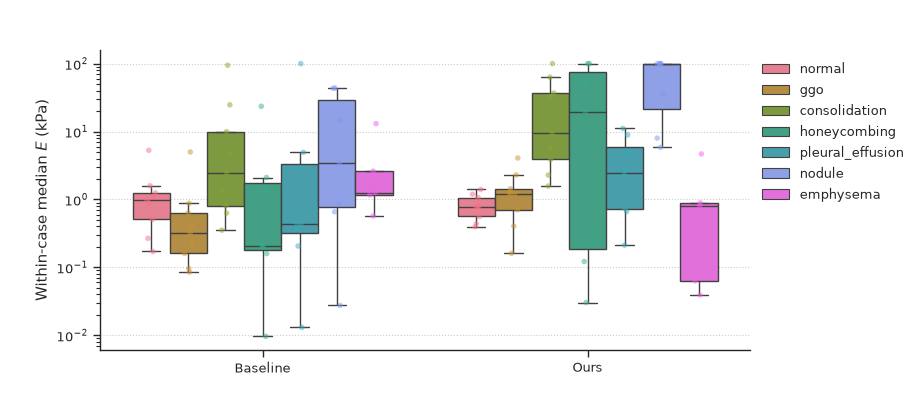

In [22]:
import project.visual.matplotlib as mpl_viz
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_regions(df, regions=None, metric='median', log=False):
    sns.set_theme(style='ticks', context='paper', font_scale=1.1)

    if regions is not None:
        df = df.loc[df['region'].isin(regions)]
    else:
        regions = df['region'].drop_duplicates().tolist()

    df = df.copy()
    df['E_kPa'] = df[metric] / 1000
    df = df.loc[np.isfinite(df['E_kPa'])]
    if log:
        df = df.loc[df['E_kPa'] > 0]
    if df.empty:
        raise ValueError('No valid results for this selection')

    methods = ['Baseline', 'Ours']
    #palette = {'Baseline': '#4477AA', 'Ours': '#EECC66'}
    palette = dict(zip(regions, sns.color_palette('husl', n_colors=len(regions))))

    fig, axes = mpl_viz.subplot_grid(
        1, 1, ax_height=3, ax_width=6.5, padding=(1.0,1.6,0.5,0.5)
    )
    ax = axes[0,0]

    common = dict(
        data=df, x='method', y='E_kPa', hue='region', ax=ax,
        order=methods, hue_order=regions, palette=palette
    )
    sns.boxplot(**common, showfliers=False)
    sns.stripplot(**common, dodge=True, jitter=0.1, size=4, alpha=0.5, legend=False)
    if log:
        ax.set_yscale('log')

    ax.set_xlabel('')
    ax.set_ylabel(f'Within-case {metric} $E$ (kPa)')
    #ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', linestyle=':')
    ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left', frameon=False, title='')
    sns.despine(fig)
    fig.tight_layout()
    return fig, ax

fig, axes = plot_regions(
    region_eval,
    regions=[
        'normal',
        'ggo',
        'consolidation',
        'honeycombing',
        'pleural_effusion',
        'nodule',
        'emphysema',
    ],
    log=True
)
plt.pause(1.0)

In [23]:
fig.savefig('bmc_regions_plot.png', bbox_inches='tight')
fig.savefig('bmc_regions_plot.pdf', bbox_inches='tight')

In [24]:
rank_eval = bmc_expt.get_rank_eval()
rank_eval.groupby('method')[['AUC_hard', 'AUC_soft']].describe()

AUC_hard                                                              \
            count      mean       std       min       25%       50%       75%   
method                                                                          
Baseline      9.0  0.518874  0.083239  0.428853  0.455472  0.500991  0.564012   
Ours          9.0  0.626654  0.108582  0.464286  0.533490  0.618782  0.724745   

                   AUC_soft                                                    \
               max    count      mean       std       min       25%       50%   
method                                                                          
Baseline  0.667113      5.0  0.402225  0.139941  0.167461  0.392861  0.446148   
Ours      0.781662      5.0  0.580705  0.151569  0.414593  0.492796  0.520566   

                              
               75%       max  
method                        
Baseline  0.478232  0.526424  
Ours      0.695318  0.780252

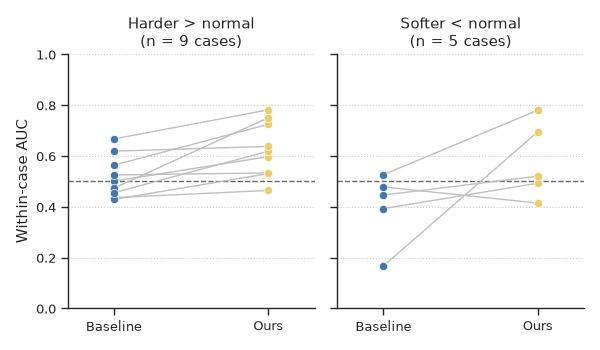

In [26]:
import matplotlib.pyplot as plt

def plot_paired_auc(df, methods=('Baseline', 'Ours')):
    metrics = {
        'AUC_hard': 'Harder > normal',
        'AUC_soft': 'Softer < normal',
    }
    colors = ['#4477AA', '#EECC66']
    fig, axes = plt.subplots(1, 2, figsize=(6, 3.5), sharey=True)

    for ax, (metric, title) in zip(axes, metrics.items()):
        paired = (
            df.pivot(index='subject', columns='method', values=metric)
            .reindex(columns=list(methods))
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        for values in paired.to_numpy():
            ax.plot([0, 1], values, color='0.75', lw=1, zorder=1)

        for x, (method, color) in enumerate(zip(methods, colors)):
            ax.scatter(
                np.full(len(paired), x),
                paired[method],
                color=color,
                edgecolor='white',
                linewidth=0.5,
                s=35,
                zorder=2
            )

        ax.axhline(0.5, color='0.4', ls='--', lw=1, zorder=0)
        ax.set(
            xticks=[0, 1],
            xticklabels=methods,
            xlim=(-0.3, 1.3),
            ylim=(0, 1),
            title=f'{title}\n(n = {len(paired)} cases)',
        )
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(axis='y', linestyle=':')

    axes[0].set_ylabel('Within-case AUC')
    fig.tight_layout()
    return fig, axes

fig, axes = plot_paired_auc(rank_eval)
plt.pause(1.0)

In [27]:
#fig.savefig('bmc_paired_auc_plot.png', bbox_inches='tight')
#fig.savefig('bmc_paired_auc_plot.pdf', bbox_inches='tight')

In [29]:
region_voxels = region_eval.groupby(['region', 'subject']).n_voxels.mean()

region_fractions = (
    region_voxels
    .div(region_voxels.loc['parenchyma'], level='subject')
    .rename('fraction')
    .reset_index()
)

largest = region_fractions.loc[
    region_fractions.groupby('region')['fraction'].idxmax()
].set_index('region')
largest

,subject,fraction
region,,
abnormal,unknown_17_3,0.430480
airways,unknown_17_1,0.019900
ambiguous,unknown_47_1,0.000003
consolidation,unknown_17_1,0.020071
emphysema,unknown_47_1,0.102860
ggo,unknown_17_3,0.030551
harder,unknown_17_3,0.037966
honeycombing,unknown_47_1,0.000990
lobes,unknown_43_1,1.081400


In [30]:
def compute_bbox(mask, pad=10):
    voxels = np.stack(np.nonzero(mask), axis=0)

    shape = np.asarray(mask.shape)
    lo = voxels.min(axis=1)
    hi = voxels.max(axis=1) + 1

    side_length = int((hi - lo).max() + 2 * pad)
    if side_length > shape.min():
        raise ValueError(f'Side length exceeds dims: {side_length} vs. {mask.shape}')

    start = (lo + hi - side_length) // 2
    start = np.clip(start, 0, shape - side_length)

    return start, start + side_length

def select_slice(lesion_mask, axis=2):
    axes = tuple(i for i in range(3) if i != axis)
    n_voxels = lesion_mask.sum(axis=axes)
    if not n_voxels.any():
        raise ValueError('No lesion voxels in this crop.')
    return int(n_voxels.argmax())

def slice_volume(vol, bbox, idx):
    lo, hi = bbox
    return vol[lo[0]:hi[0],lo[1]:hi[1],idx].T


In [66]:
import project.visual.matplotlib as mpl_viz
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize

def plot_clinical_grid(expt, protocol_vals, selections, cmap='magma'):

    images = expt.images
    masks = expt.masks
    E_preds = {
        'Ours': expt.E_train[protocol_vals],
        'Baseline': expt.E_optim[protocol_vals]
    }
    method_order = ['Ours', 'Baseline']

    fig, axes, cax = mpl_viz.subplot_grid(
        n_rows=len(selections),
        n_cols=2 + len(method_order),
        ax_height=2,
        ax_width=2,
        spacing=0,
        padding=(0.0, 0.0, 0.0, 0.3),
        cbar_width=0.2
    )

    for ax, title in zip(axes[0], ['Reference CT', 'Region overlay', 'Our method', 'Baseline']):
        ax.set_title(title)

    for row, (case_id, lesion_name) in enumerate(selections):
        img = images[case_id]
        mask = masks[case_id]['lobes']
        lesion = masks[case_id][lesion_name]

        bbox = compute_bbox(mask)
        idx = select_slice(lesion)

        img_slice = slice_volume(img, bbox, idx)
        mask_slice = slice_volume(mask, bbox, idx)
        lesion_slice = slice_volume(lesion, bbox, idx)

        for ax in axes[row]:
            ax.imshow(img_slice, origin='lower', cmap='gray', clim=(-1000, 0))

        # transparent background with orange overlay
        overlay_color = [1.0, 0.5, 1.0]
        overlay = np.zeros((*lesion_slice.shape, 4))
        overlay[lesion_slice] = overlay_color + [0.5]

        axes[row, 1].imshow(overlay, origin='lower', interpolation='nearest')
        axes[row, 1].contour(
            lesion_slice.astype(float),
            levels=[0.5],
            colors=overlay_color,
            linewidths=0.7,
            origin='lower'
        )

        norm = LogNorm(vmin=0.1, vmax=100) # kPa
        #norm = Normalize(vmin=0, vmax=20) # kPa

        for col, method in enumerate(method_order, start=2):
            E_pred = E_preds[method][case_id]
            E_vals = slice_volume(E_pred, bbox, idx) / 1000
            E_vals = np.ma.masked_where(
                ~mask_slice | ~np.isfinite(E_vals) | (E_vals <= 0), E_vals
            )
            im = axes[row, col].imshow(E_vals, origin='lower', cmap=cmap, norm=norm)

            axes[row, col].contour(
                lesion_slice.astype(float),
                levels=[0.5],
                colors='white',
                linewidths=0.7,
                origin='lower'
            )

        label = lesion_name.replace('_', ' ').capitalize()
        axes[row, 0].set_ylabel(f'{case_id}\n{label}')

    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])

    cbar = fig.colorbar(im, cax=cax) #, extend='min')
    cbar.set_label('E (kPa)')
    #cbar.set_ticks([0.01, 0.1, 1, 10, 100])
    #cbar.set_ticklabels(['0.01', '0.1', '1', '10', '100'])

    return fig, axes


selections = {
    'val': [
        ('unknown_39_1', 'ggo'),
        ('unknown_51_1', 'consolidation'),
        ('unknown_18_1', 'nodule'),
        ('unknown_27_1', 'emphysema'),
    ],
    'test': [
        ('unknown_17_3', 'ggo'),
        ('unknown_17_1', 'consolidation'),
        ('unknown_29_1', 'nodule'),
        ('unknown_47_1', 'emphysema'),
    ]
}

#fig, axes = plot_clinical_grid(bmc_expt, (0, 'LE'), selections)
#fig

In [37]:
fig.savefig('bmc_clinical_grid.png', bbox_inches='tight')
fig.savefig('bmc_clinical_grid.pdf', bbox_inches='tight')

# BMC TV regularization sweep

In [38]:
base_prefix = '../bmc-4dct/2026-11-17'
protocol_keys = ['params.tv_reg_weight']

bmc_tv_expt = evaluation.Experiment(base_prefix, protocol_keys, case_split)

Loading job metadata
Loading evaluation metrics


100%|██████████| 108/108 [00:00<00:00, 172.07it/s]

Selecting best train epochs


,params.random_seed,epoch,loss
params.tv_reg_weight,,,
0.00001,0,25,0.039909
0.00010,0,24,0.040601
0.00100,0,24,0.041390
0.00300,0,20,0.045292
0.00500,2,18,0.047004
0.01000,2,18,0.047911


In [39]:
bmc_tv_expt.images = bmc_expt.images
bmc_tv_expt.masks = bmc_expt.masks

In [40]:
bmc_tv_expt.evaluate_protocol((0.003,), phase='test')

Evaluating protocol: (0.003,)
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-17_train/job_bb8d9b80173f7e8f/config/7376b2cbfa0ad26e.yaml
dict(len=4)
├── 'dataset':       dict(len=6)
|   ├── 'name':          'BMC-4DCT'
|   ├── 'root':          '/restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT'
|   ├── 'subjects':      '4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4DCT_7_3,4DCT_8_1,4DCT_8_2,4DCT_10_1,unknown_12_1,unknown_13_1,unknown_14_1,unknown_15_1,unknown_16_1,unknown_17_1,unknown_17_3,unknown_18_1,unknown_19_1,unknown_20_1,unknown_22_1,unknown_23_1,unknown_26_1,unknown_27_1,unknown_28_1,unknown_29_1,unknown_30_1,unknown_31_1,unknown_32_1,unknown_33_1,unknown_34_1,unknown_36_1,unknown_37_1,unknown_38_1,unknown_39_1,unknown_40_1,unknown_40_5,unknown_42_1,unknown_42_4,unknown_43_1,unknown_44_1,unknown_45_1,unknown_47_1,unknown_49_1,unknown_50_1,unknown_51_1,unknown_52_1,unknown_53_1'
|   ├── 'state_pairs':   list(len=1)
|   |   └── 0: list(len=2)
|   |

  0%|          | 0/9 [00:00<?, ?it/s]

Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-17_optimize/job_5dab9fe7d13f9853/outputs/optimize/default/unknown_17_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-17_optimize/job_8c302a66f032307b/outputs/optimize/default/unknown_17_3/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-17_optimize/job_4ca7ecb709f9a886/outputs/optimize/default/unknown_28_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-17_optimize/job_df68fae3fcb6b220/outputs/optimize/default/unknown_29_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-17_optimize/job_6f7bad404baec5a3/outputs/optimize/default/unknown_30_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-17_optimize/job_65931943677bde7e/outputs/optimize/default/unknown_31_1/ra

In [41]:
tv_region_eval = bmc_tv_expt.get_region_eval()

/scratch/8767267.1.batcomputer/ipykernel_781922/3587338253.py:46: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


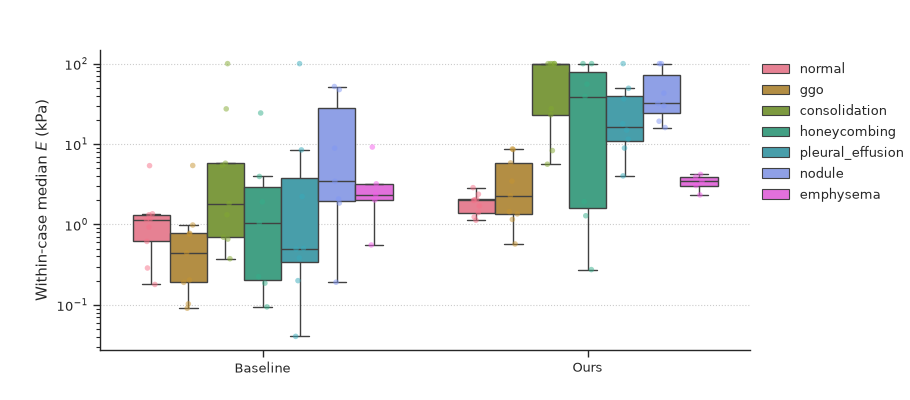

In [42]:
fig, axes = plot_regions(
    tv_region_eval,
    regions=[
        'normal',
        'ggo',
        'consolidation',
        'honeycombing',
        'pleural_effusion',
        'nodule',
        'emphysema',
    ],
    log=True
)

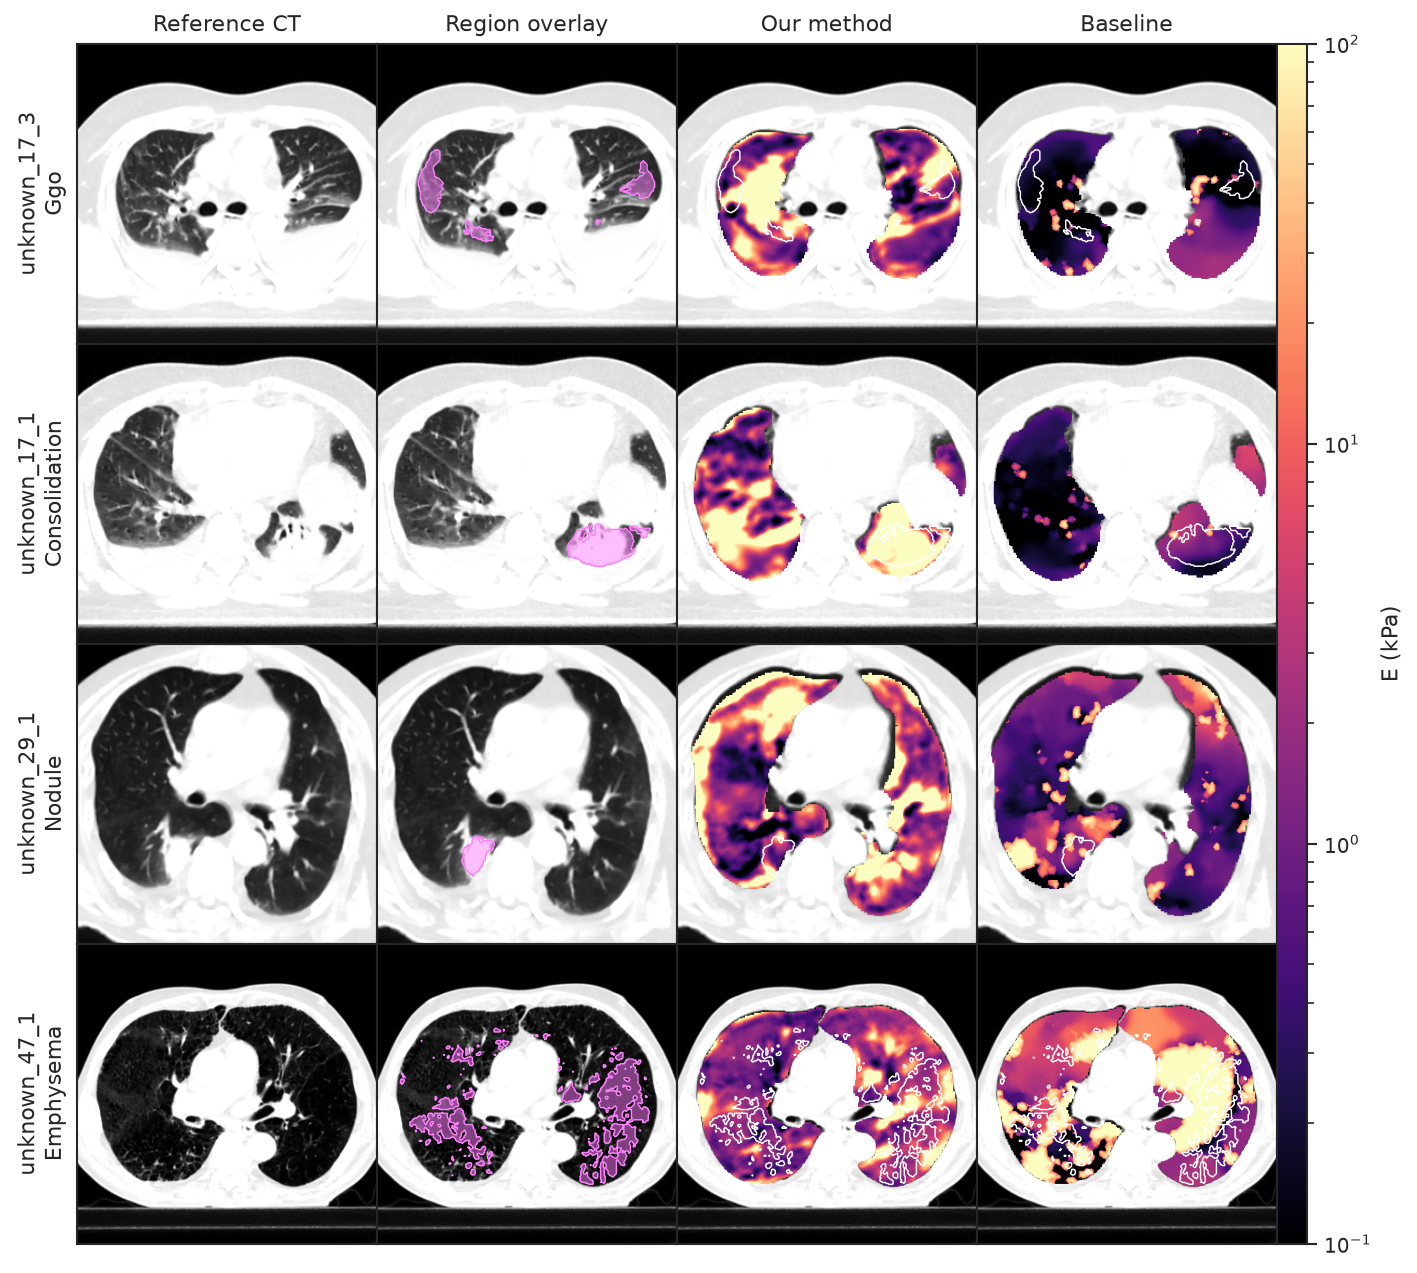

In [44]:
fig, axes = plot_clinical_grid(bmc_tv_expt, (0.003,), selections)
fig

In [91]:
tv_reg_weights = [1e-5, 1e-4, 1e-3, 3e-3, 5e-3, 1e-2]

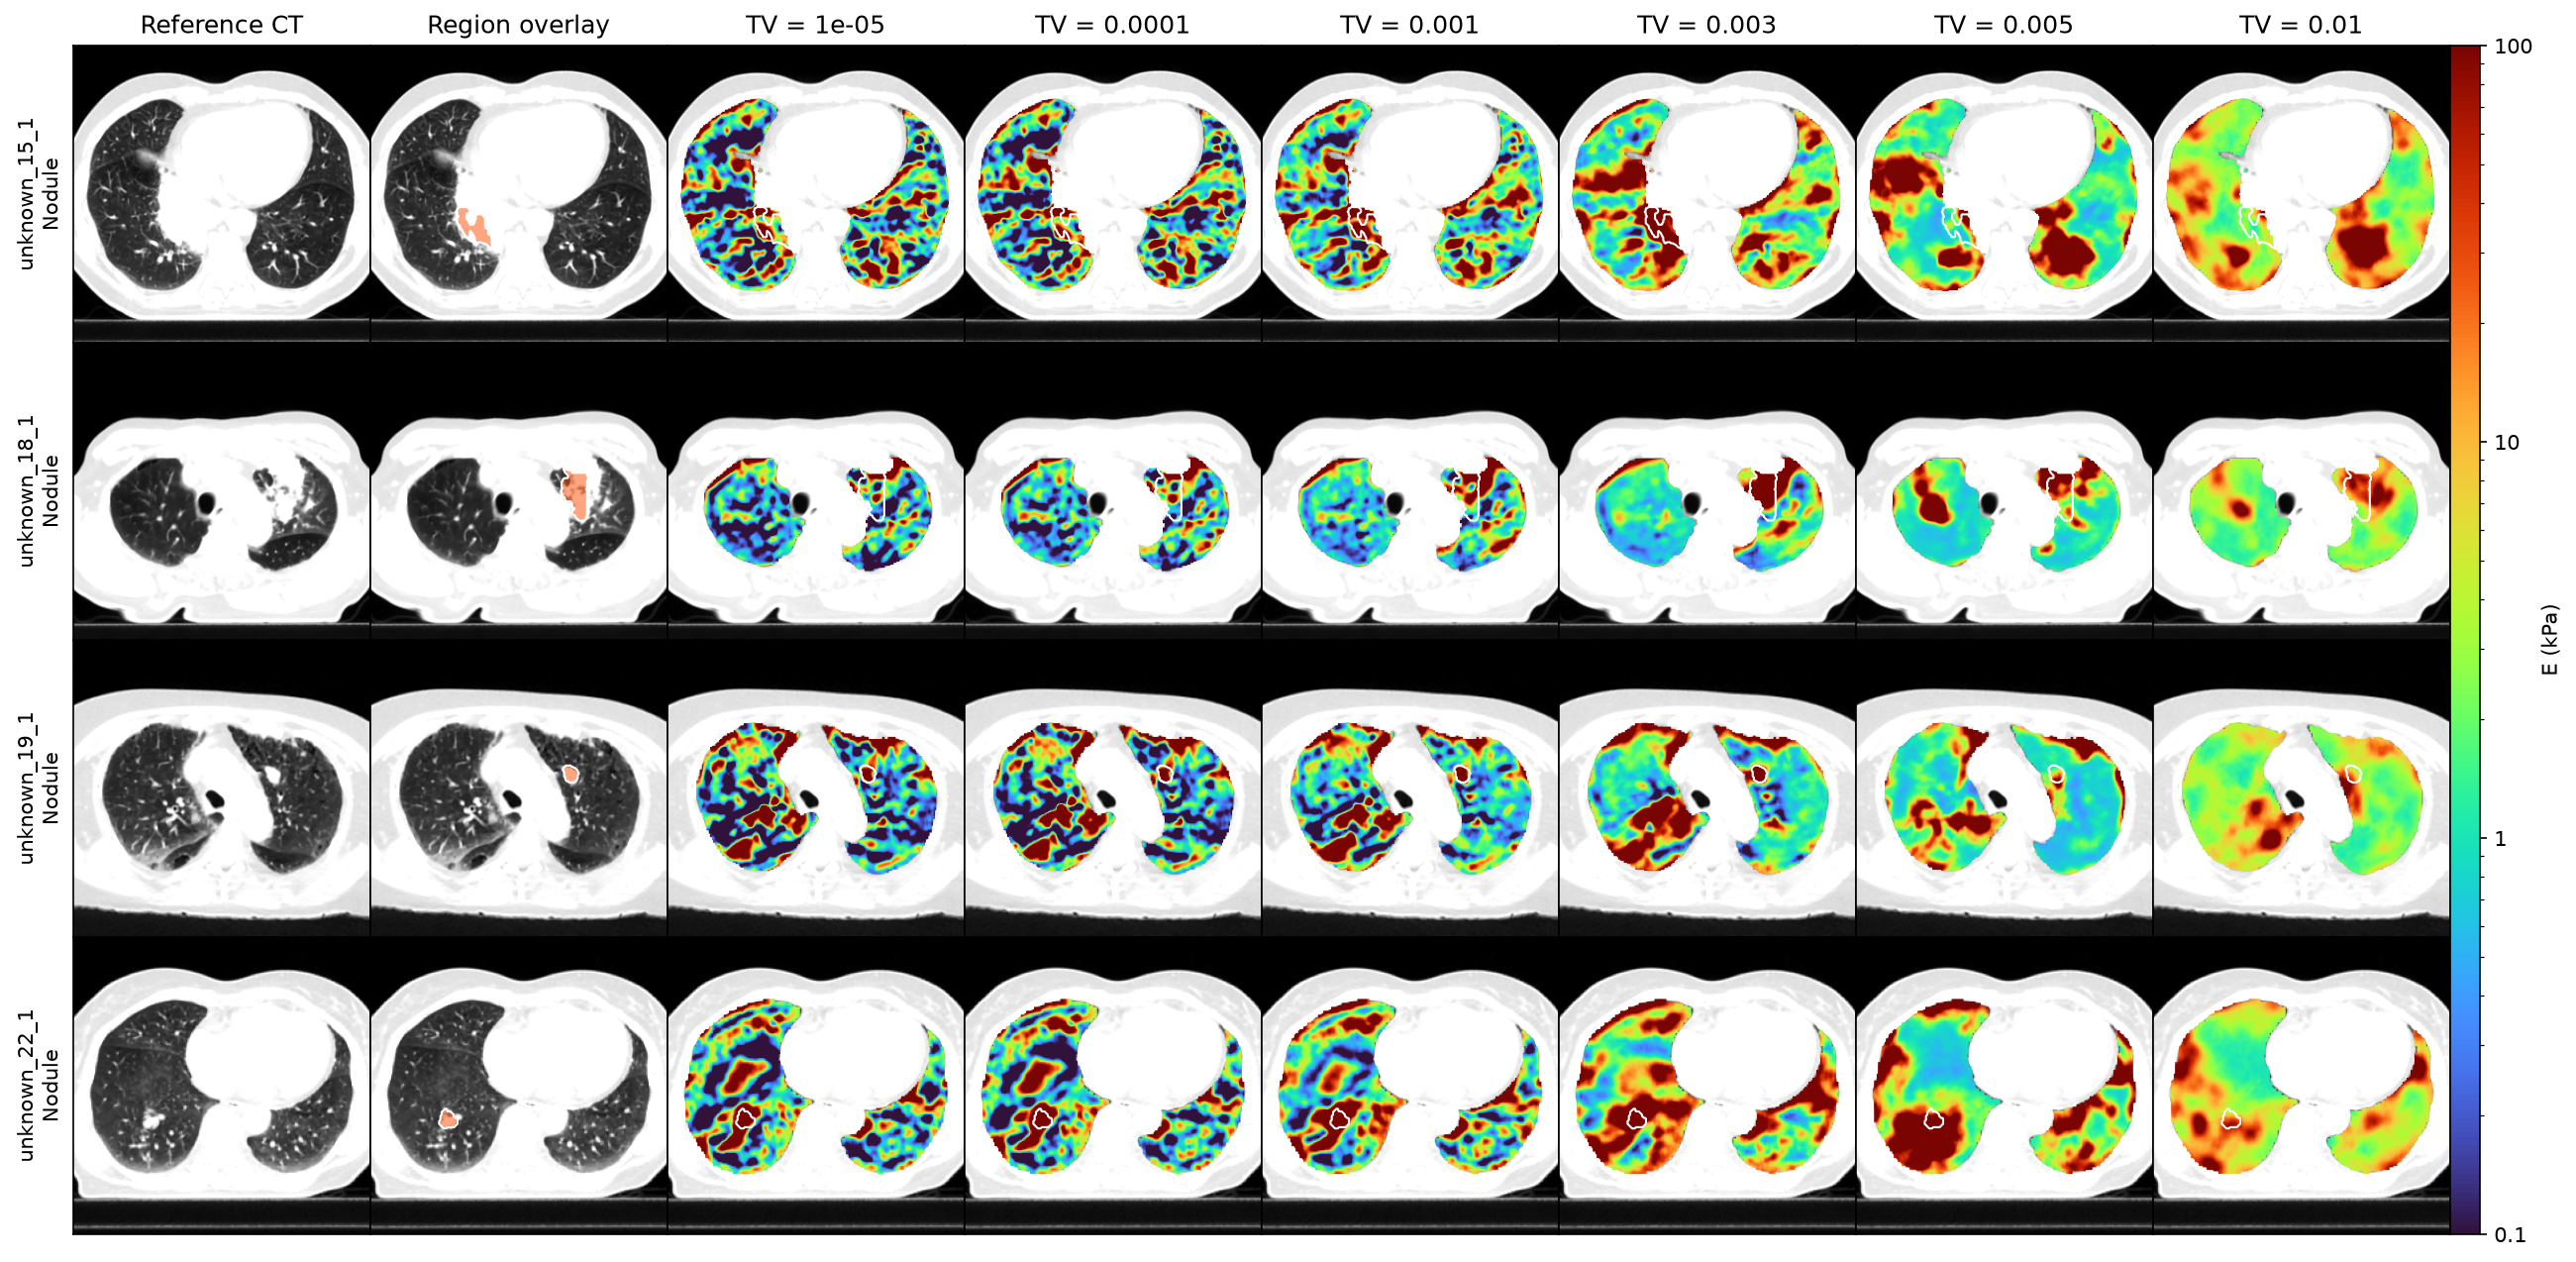

In [102]:
case_ids = case_split['val'][:4]

def plot_tv_reg_sweep(E_grid, lesion_name):

    fig, axes, cax = mpl_viz.subplot_grid(
        n_rows=len(case_ids),
        n_cols=2 + len(tv_reg_weights),
        ax_height=2,
        ax_width=2,
        spacing=0,
        padding=(0.0, 0.0, 0.0, 0.3),
        cbar_width=0.2
    )

    axes[0,0].set_title('Reference CT')
    axes[0,1].set_title('Region overlay')
    for i, weight in enumerate(tv_reg_weights):
        axes[0,2+i].set_title(f'TV = {weight:g}')

    for row, case_id in enumerate(case_ids):

        img = images[case_id]
        mask = masks[case_id]['lobes']
        lesion = masks[case_id][lesion_name] * mask

        bbox = compute_bbox(mask)
        idx = select_slice(lesion)

        img_slice = slice_volume(img, bbox, idx)
        mask_slice = slice_volume(mask, bbox, idx)
        lesion_slice = slice_volume(lesion, bbox, idx)

        for ax in axes[row]:
            ax.imshow(img_slice, origin='lower', cmap='gray', clim=(-1000, 0))

        # transparent background with orange overlay
        overlay = np.zeros((*lesion_slice.shape, 4))
        overlay[lesion_slice] = [1.0, 0.3, 0.0, 0.5]

        axes[row, 1].imshow(overlay, origin='lower', interpolation='nearest')
        axes[row, 1].contour(
            lesion_slice.astype(float),
            levels=[0.5],
            colors='white',
            linewidths=1.0,
            origin='lower'
        )

        norm = LogNorm(vmin=0.1, vmax=100) # kPa
        #norm = Normalize(vmin=0.1, vmax=100)
        
        for col, weight in enumerate(tv_reg_weights, start=2):
            E_pred = E_grid[weight][case_id]
            E_vals = slice_volume(E_pred, bbox, idx) / 1000
            E_vals = np.ma.masked_where(
                ~mask_slice | ~np.isfinite(E_vals) | (E_vals <= 0),
                E_vals
            )
            im = axes[row, col].imshow(E_vals, origin='lower', cmap='turbo', norm=norm)

            axes[row, col].contour(
                lesion_slice.astype(float),
                levels=[0.5],
                colors='white',
                linewidths=1.0,
                origin='lower'
            )

        label = lesion_name.replace('_', ' ').capitalize()
        axes[row, 0].set_ylabel(f'{case_id}\n{label}')

    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])

    cbar = fig.colorbar(im, cax=cax) #, extend='min')
    cbar.set_label('E (kPa)')
    cbar.set_ticks([0.1, 1, 10, 100])
    cbar.set_ticklabels(['0.1', '1', '10', '100'])

    return fig, axes

fig, axes = plot_tv_reg_sweep(E_tv_train, 'nodule')
fig

In [ ]:
fig, axes = plot_tv_reg_sweep(E_tv_optim, 'nodule')
fig

In [103]:
regions = ['ggo', 'consolidation', 'nodule', 'emphysema']

region_medians = region_eval.pivot(
    index=['method', 'case_id', 'tv_reg_weight'],
    columns='region',
    values='median',
).div(1000)

region_ratios = region_medians[regions].div(
    region_medians['normal'].where(region_medians['normal'] > 0),
    axis=0,
)

display(
    region_ratios.groupby(['method', 'tv_reg_weight']).median()
)

region                       ggo  consolidation      nodule  emphysema
method   tv_reg_weight                                                
Baseline 0.00001        0.498668       0.920922    1.474926   1.258856
         0.00010        0.551975       0.700199    1.279179   1.161804
         0.00100        0.445551       0.848449    1.346543   1.702397
         0.00300        0.470391       1.000000    1.438455   1.598644
         0.00500        0.724011       0.785629    1.755703   1.622746
         0.01000        1.000000       0.689782    1.771398   1.628516
Ours     0.00001        1.005672       3.130600  136.398015   0.599346
         0.00010        1.099279       3.778890  122.251487   0.719463
         0.00100        1.490824       8.546017   77.416394   1.014061
         0.00300        1.741273       9.131536   42.730339   0.944269
         0.00500        1.286251       3.298932   15.440881   1.149755
         0.01000        1.137674       2.851186    2.143895   1.095748

In [104]:
rank_eval.groupby(['method', 'tv_reg_weight'])[['AUC_hard', 'AUC_soft']].agg(['mean', 'std', 'median'])

AUC_hard                      AUC_soft            \
                            mean       std    median      mean       std   
method   tv_reg_weight                                                     
Baseline 0.00001        0.444093  0.144047  0.468123  0.449072  0.112349   
         0.00010        0.446051  0.149040  0.465609  0.436906  0.103897   
         0.00100        0.438289  0.167035  0.454810  0.384381  0.102567   
         0.00300        0.441646  0.185233  0.423822  0.378280  0.106059   
         0.00500        0.449400  0.190378  0.433528  0.362183  0.090543   
         0.01000        0.464449  0.194643  0.437689  0.374258  0.084431   
Ours     0.00001        0.570648  0.055791  0.556619  0.588257  0.199253   
         0.00010        0.578589  0.053861  0.558951  0.587534  0.177328   
         0.00100        0.608959  0.067247  0.580756  0.543294  0.229623   
         0.00300        0.648151  0.076108  0.599285  0.522887  0.224088   
         0.00500        0.579143  0.090235  0.589231  0.505243  0.128458   
         0.01000        0.617574  0.113069  0.587484  0.489112  0.134391   

                                  
                          median  
method   tv_reg_weight            
Baseline 0.00001        0.455012  
         0.00010        0.458329  
         0.00100        0.422042  
         0.00300        0.404299  
         0.00500        0.399145  
         0.01000        0.408236  
Ours     0.00001        0.561492  
         0.00010        0.551615  
         0.00100        0.501374  
         0.00300        0.505423  
         0.00500        0.483876  
         0.01000        0.481879

# Soft clamp beta sweep

In [50]:
base_prefix = '../bmc-4dct/2026-11-18'
protocol_keys = ['params.E_beta']

bmc_beta_expt = evaluation.Experiment(base_prefix, protocol_keys, case_split)

Loading job metadata
Loading evaluation metrics


100%|██████████| 54/54 [00:00<00:00, 184.58it/s]


Selecting best train epochs


,params.random_seed,epoch,loss
params.E_beta,,,
1.0,0,23,0.042954
5.0,0,23,0.041048
hard clamp,0,17,0.041048


In [54]:
bmc_expt.load_assets(phase='val')

Loading common assets
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-15_train/job_20dcd12aa42a2ede/config/7376b2cbfa0ad26e.yaml
dict(len=4)
├── 'dataset':       dict(len=6)
|   ├── 'name':          'BMC-4DCT'
|   ├── 'root':          '/restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT'
|   ├── 'subjects':      '4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4DCT_7_3,4DCT_8_1,4DCT_8_2,4DCT_10_1,unknown_12_1,unknown_13_1,unknown_14_1,unknown_15_1,unknown_16_1,unknown_17_1,unknown_17_3,unknown_18_1,unknown_19_1,unknown_20_1,unknown_22_1,unknown_23_1,unknown_26_1,unknown_27_1,unknown_28_1,unknown_29_1,unknown_30_1,unknown_31_1,unknown_32_1,unknown_33_1,unknown_34_1,unknown_36_1,unknown_37_1,unknown_38_1,unknown_39_1,unknown_40_1,unknown_40_5,unknown_42_1,unknown_42_4,unknown_43_1,unknown_44_1,unknown_45_1,unknown_47_1,unknown_49_1,unknown_50_1,unknown_51_1,unknown_52_1,unknown_53_1'
|   ├── 'state_pairs':   list(len=1)
|   |   └── 0: list(len=2)
|   |       ├

In [55]:
bmc_beta_expt.images = bmc_expt.images
bmc_beta_expt.masks = bmc_expt.masks

In [56]:
%%time
bmc_beta_expt.evaluate_all(phase='val') # ~8 minutes

Evaluating protocol: 1.0
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_train/job_3b8eafb296d15ba2/config/7376b2cbfa0ad26e.yaml
dict(len=4)
├── 'dataset':       dict(len=6)
|   ├── 'name':          'BMC-4DCT'
|   ├── 'root':          '/restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT'
|   ├── 'subjects':      '4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4DCT_7_3,4DCT_8_1,4DCT_8_2,4DCT_10_1,unknown_12_1,unknown_13_1,unknown_14_1,unknown_15_1,unknown_16_1,unknown_17_1,unknown_17_3,unknown_18_1,unknown_19_1,unknown_20_1,unknown_22_1,unknown_23_1,unknown_26_1,unknown_27_1,unknown_28_1,unknown_29_1,unknown_30_1,unknown_31_1,unknown_32_1,unknown_33_1,unknown_34_1,unknown_36_1,unknown_37_1,unknown_38_1,unknown_39_1,unknown_40_1,unknown_40_5,unknown_42_1,unknown_42_4,unknown_43_1,unknown_44_1,unknown_45_1,unknown_47_1,unknown_49_1,unknown_50_1,unknown_51_1,unknown_52_1,unknown_53_1'
|   ├── 'state_pairs':   list(len=1)
|   |   └── 0: list(len=2)
|   |     

  0%|          | 0/9 [00:00<?, ?it/s]

Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_4eda2d2b65768de0/outputs/optimize/default/unknown_15_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_f16e163d7ff3006b/outputs/optimize/default/unknown_18_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_65e750e4b2fa54fa/outputs/optimize/default/unknown_19_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_8d7e491bde20ffec/outputs/optimize/default/unknown_22_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_f91da1035d372c02/outputs/optimize/default/unknown_27_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_f6b597956f0804b0/outputs/optimize/default/unknown_39_1/ra

  0%|          | 0/9 [00:00<?, ?it/s]

Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_e2f798e619c39864/outputs/optimize/default/unknown_15_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_b566d71e760f6ef7/outputs/optimize/default/unknown_18_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_4b1d590b8d1f11aa/outputs/optimize/default/unknown_19_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_d0ce901f9ec13455/outputs/optimize/default/unknown_22_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_7e3e28df22a4568d/outputs/optimize/default/unknown_27_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_2a20e89d7f039d0c/outputs/optimize/default/unknown_39_1/ra

  0%|          | 0/9 [00:00<?, ?it/s]

Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_95434cb81931dc6b/outputs/optimize/default/unknown_15_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_16a16e047ddc6842/outputs/optimize/default/unknown_18_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_14741c786c94037f/outputs/optimize/default/unknown_19_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_c381298070ae64a7/outputs/optimize/default/unknown_22_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_3dfde118d23589e5/outputs/optimize/default/unknown_27_1/rasters/E_pred.nii.gz
Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-18_optimize/job_186279cdb1624018/outputs/optimize/default/unknown_39_1/ra

In [59]:
beta_region_eval = bmc_beta_expt.get_region_eval(phase)
beta_rank_eval = bmc_beta_expt.get_rank_eval(phase)

In [61]:
beta_rank_eval.groupby(['method', 'params.E_beta'])[['AUC_hard', 'AUC_soft']].agg(['mean', 'std', 'median'])

AUC_hard                      AUC_soft            \
                            mean       std    median      mean       std   
method   params.E_beta                                                     
Baseline 1.0            0.432669  0.140085  0.440992  0.422199  0.113679   
         5.0            0.437411  0.146291  0.458272  0.442733  0.112007   
         hard clamp     0.443353  0.149231  0.465644  0.438290  0.099748   
Ours     1.0            0.620761  0.062450  0.621823  0.621543  0.171609   
         5.0            0.600020  0.058751  0.590621  0.590153  0.190433   
         hard clamp     0.585728  0.048771  0.570063  0.573964  0.174998   

                                  
                          median  
method   params.E_beta            
Baseline 1.0            0.464966  
         5.0            0.485015  
         hard clamp     0.456393  
Ours     1.0            0.650178  
         5.0            0.538934  
         hard clamp     0.534335

In [ ]:
fig, ax = plot_regions(beta_region_eval)
fig

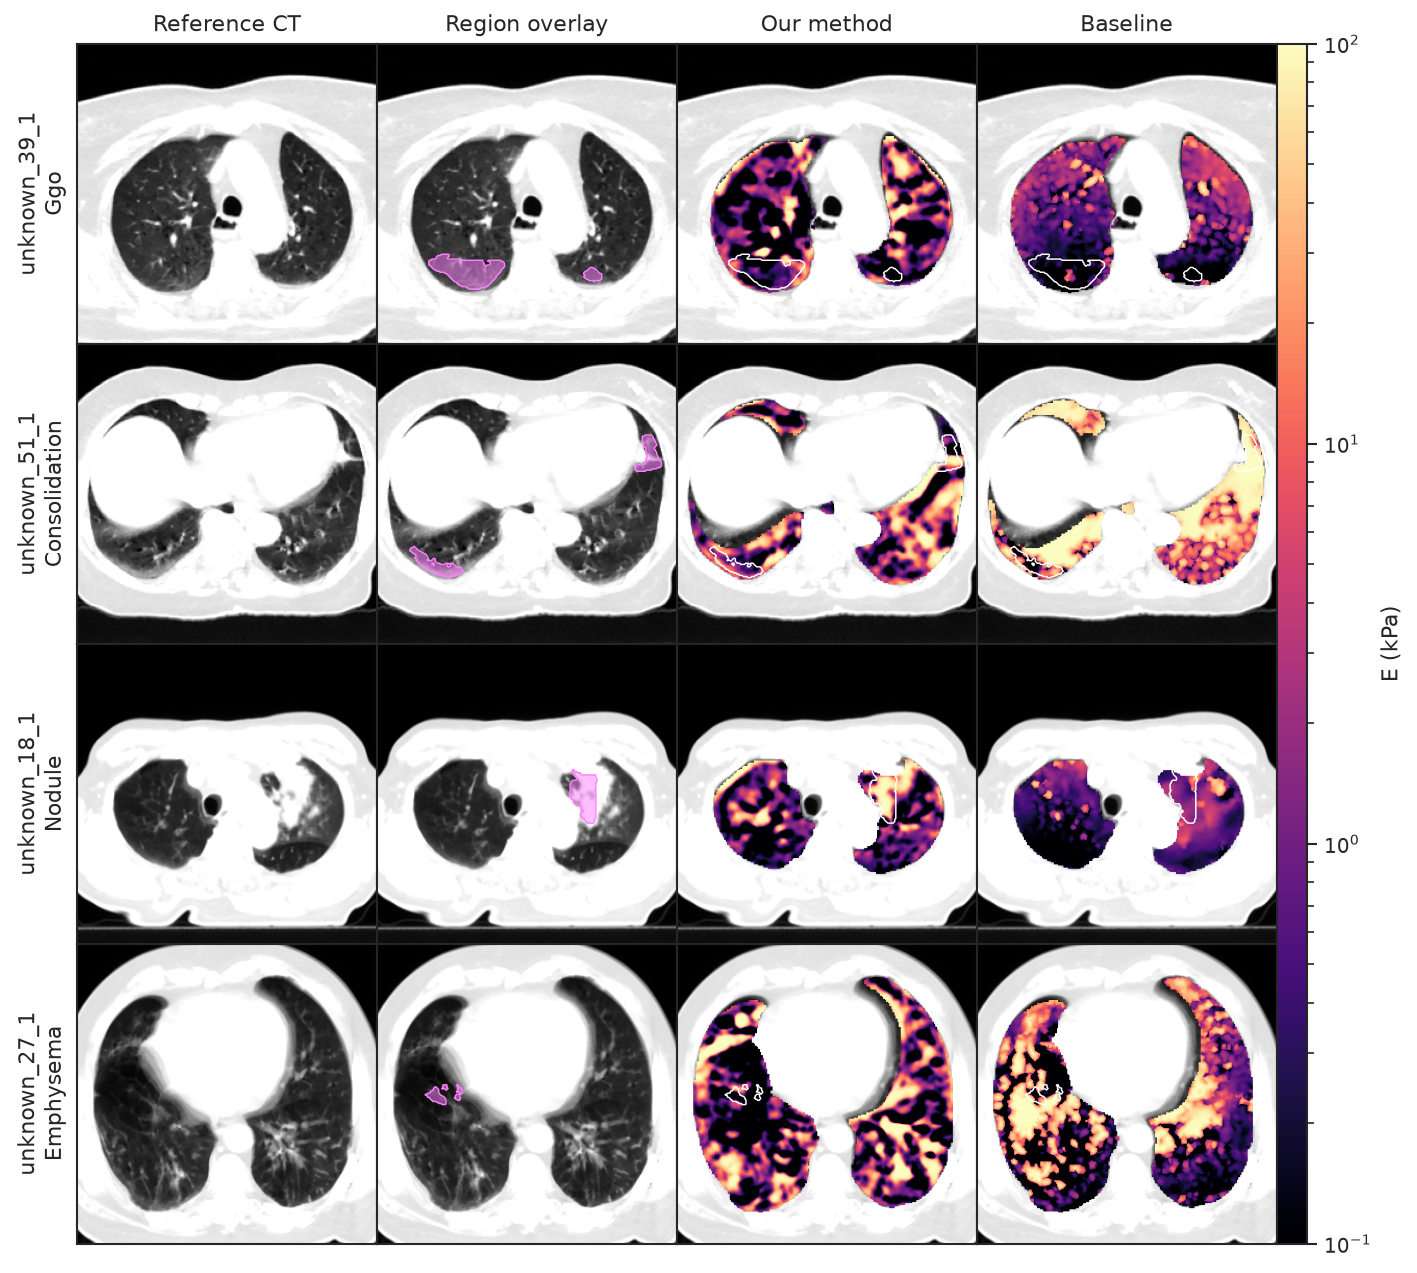

In [69]:
fig, axes = plot_clinical_grid(bmc_beta_expt, ('1.0',), selections['val'])
fig

In [ ]:
beta_labels = ['hard clamp', '5.0', '1.0']

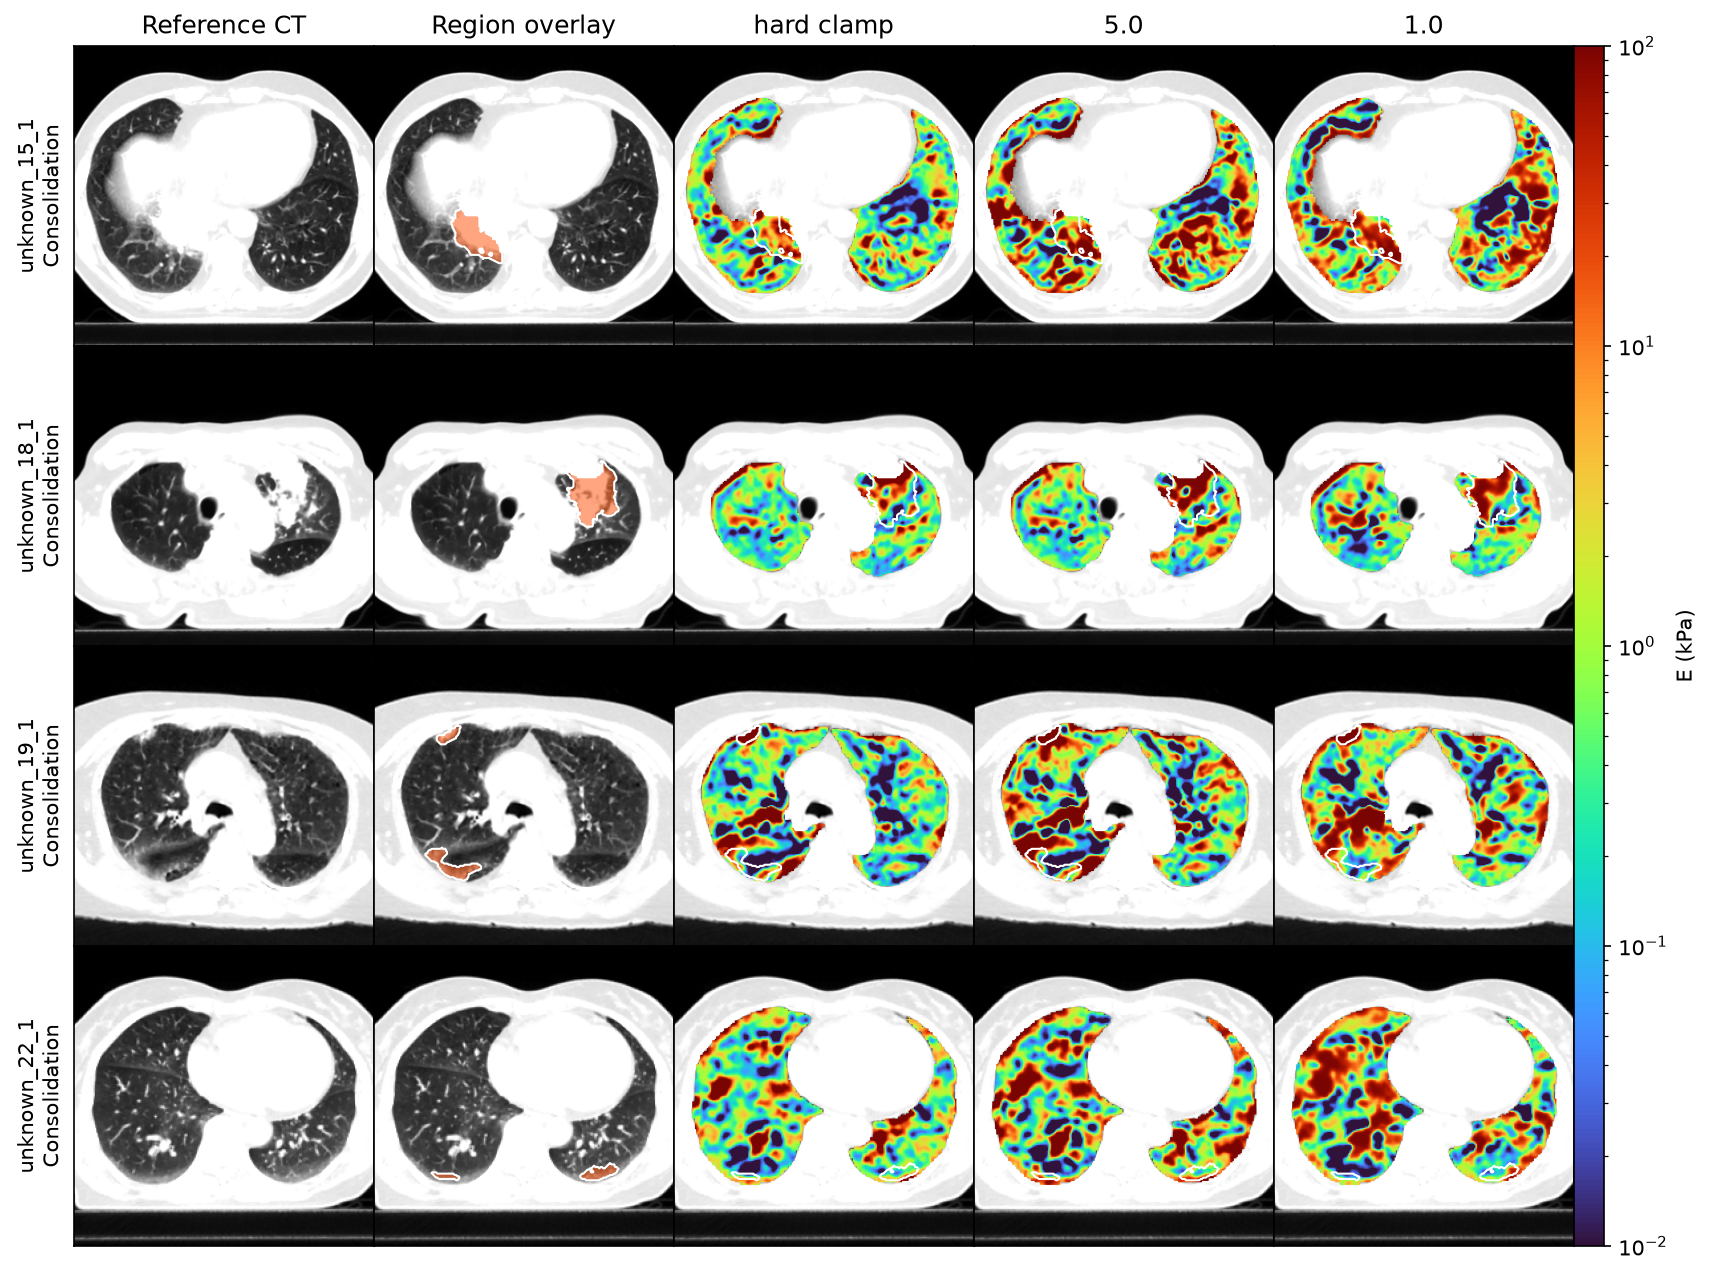

In [254]:
case_ids = case_split['val'][:4]

def plot_beta_sweep(E_grid, lesion_name, cmap='turbo'):

    fig, axes, cax = mpl_viz.subplot_grid(
        n_rows=len(case_ids),
        n_cols=5,
        ax_height=2,
        ax_width=2,
        spacing=0,
        padding=(0.0, 0.0, 0.0, 0.3),
        cbar_width=0.2
    )

    axes[0,0].set_title('Reference CT')
    axes[0,1].set_title('Region overlay')
    for i, beta in enumerate(beta_labels):
        axes[0,2+i].set_title(beta)

    for row, case_id in enumerate(case_ids):

        img = images[case_id]
        mask = masks[case_id]['lobes']
        lesion = masks[case_id][lesion_name] * mask

        bbox = compute_bbox(mask)
        idx = select_slice(lesion)

        img_slice = slice_volume(img, bbox, idx)
        mask_slice = slice_volume(mask, bbox, idx)
        lesion_slice = slice_volume(lesion, bbox, idx)

        for ax in axes[row]:
            ax.imshow(img_slice, origin='lower', cmap='gray', clim=(-1000, 0))

        # transparent background with orange overlay
        overlay = np.zeros((*lesion_slice.shape, 4))
        overlay[lesion_slice] = [1.0, 0.3, 0.0, 0.5]

        axes[row, 1].imshow(overlay, origin='lower', interpolation='nearest')
        axes[row, 1].contour(
            lesion_slice.astype(float),
            levels=[0.5],
            colors='white',
            linewidths=1.0,
            origin='lower'
        )

        norm = LogNorm(vmin=0.01, vmax=100) # kPa
        #norm = Normalize(vmin=0.1, vmax=100)
        
        for col, beta in enumerate(beta_labels, start=2):
            if beta not in E_grid:
                raise Exception
            E_pred = E_grid[beta][case_id]
            E_vals = slice_volume(E_pred, bbox, idx) / 1000
            E_vals = np.ma.masked_where(
                ~mask_slice | ~np.isfinite(E_vals) | (E_vals <= 0),
                E_vals
            )
            im = axes[row, col].imshow(E_vals, origin='lower', cmap=cmap, norm=norm)

            axes[row, col].contour(
                lesion_slice.astype(float),
                levels=[0.5],
                colors='white',
                linewidths=1.0,
                origin='lower'
            )

        label = lesion_name.replace('_', ' ').capitalize()
        axes[row, 0].set_ylabel(f'{case_id}\n{label}')

    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])

    cbar = fig.colorbar(im, cax=cax) #, extend='min')
    cbar.set_label('E (kPa)')
    #cbar.set_ticks([0.1, 1, 10, 100])
    #cbar.set_ticklabels(['0.1', '1', '10', '100'])

    return fig, axes

fig, axes = plot_beta_sweep(E_beta_train, 'consolidation', cmap='turbo')
fig

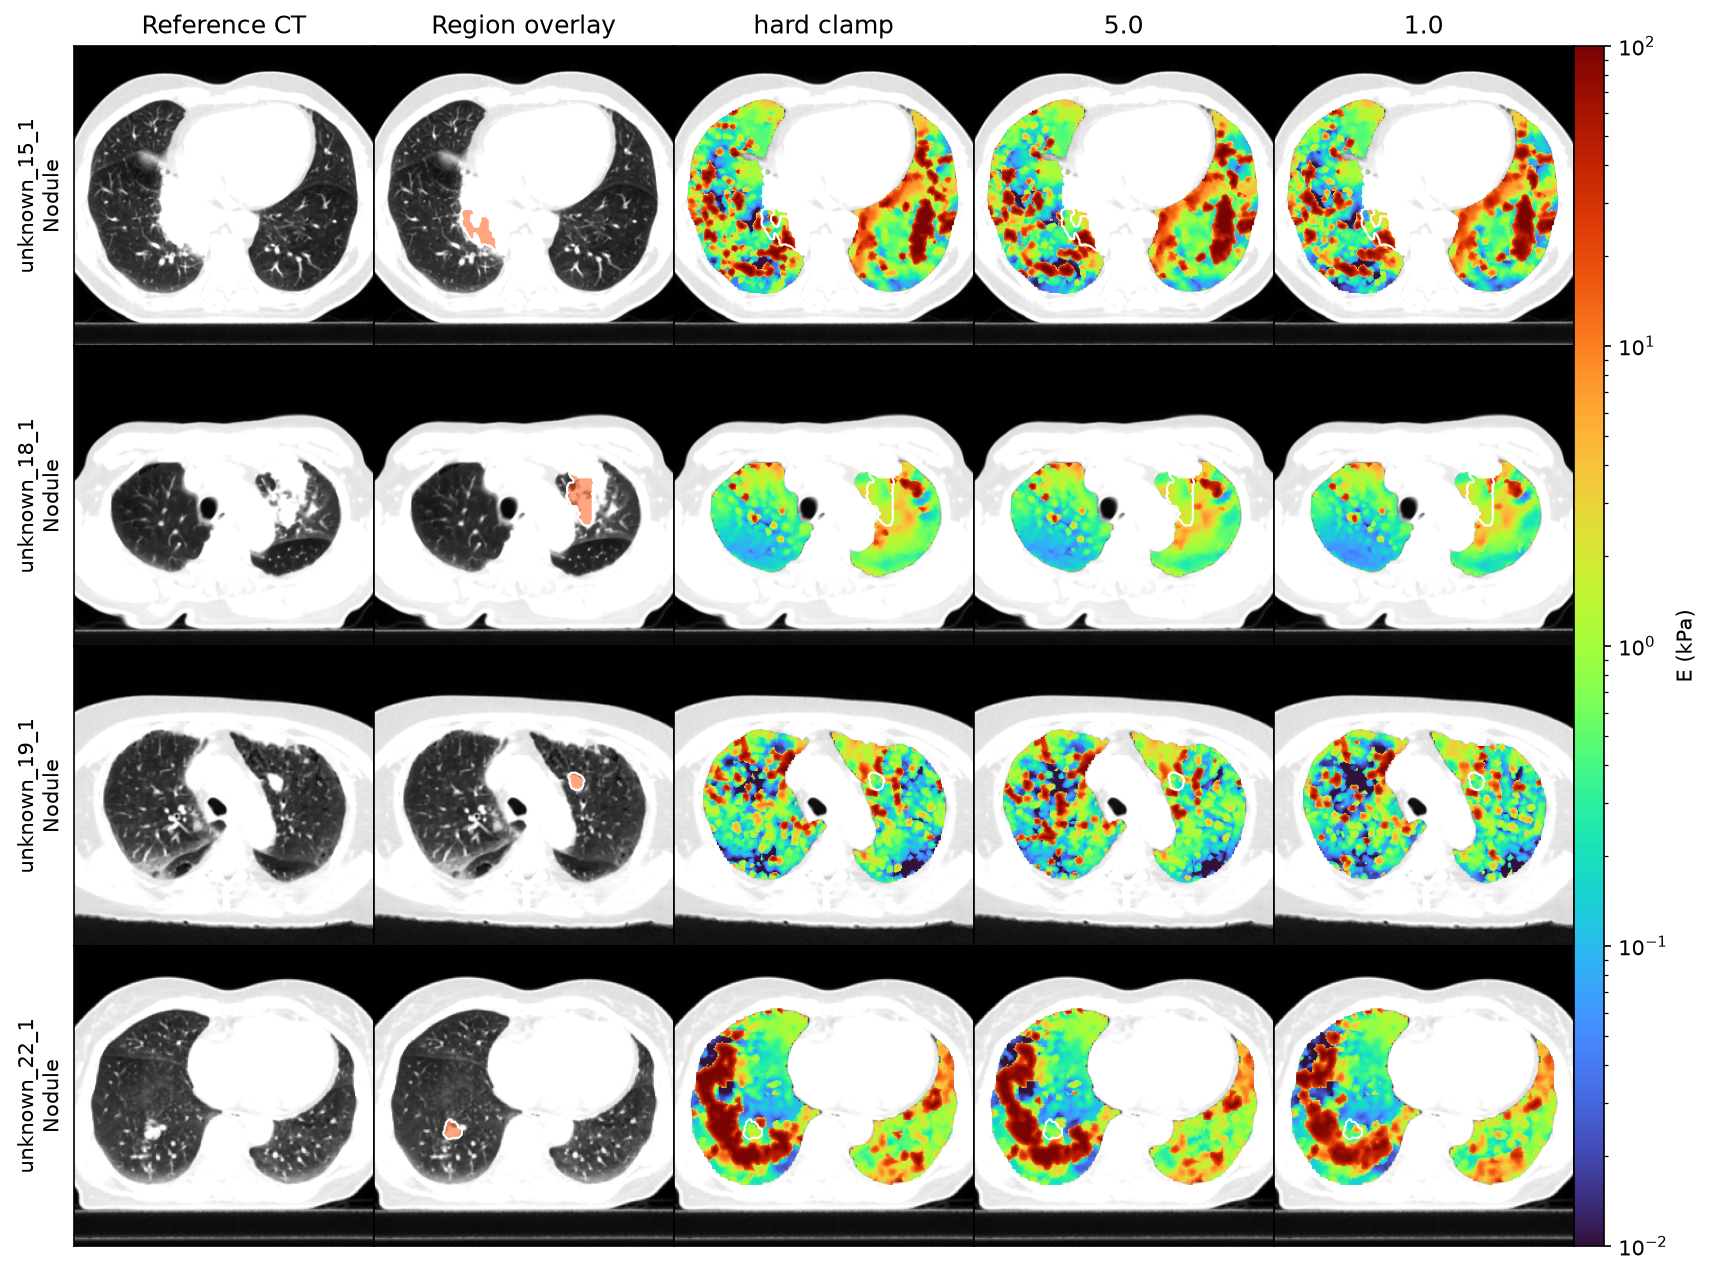

In [255]:
fig, axes = plot_beta_sweep(E_beta_optim, 'nodule', cmap='turbo')
fig